<style>
.reveal{font-family:"Helvetica Neue",Helvetica,Arial,sans-serif;font-size:30px;color:#2d3436}
.reveal-viewport{background:linear-gradient(135deg,#fdfbfb 0%,#ebedee 100%)}
.reveal h1,.reveal h2,.reveal h3{font-family:inherit;text-transform:none;font-weight:700;color:#c2185b;letter-spacing:-0.5px}
.reveal h1{font-size:2em}.reveal h2{font-size:1.5em;border-bottom:4px solid #f8bbd0;padding-bottom:.2em;display:inline-block}
.reveal .slides section{text-align:left}
.reveal .slides section>h1:only-child,.reveal .slides section>h1:first-child{text-align:center}
.reveal strong{color:#ad1457}
.reveal ul,.reveal ol{display:block}
.reveal li{margin:.35em 0}
.reveal table{margin:0 auto;border-collapse:collapse;font-size:.65em;box-shadow:0 4px 14px rgba(0,0,0,.12);border-radius:8px;overflow:hidden}
.reveal table th{background:#c2185b;color:#fff;padding:.5em 1em;text-align:left}
.reveal table td{padding:.4em 1em;border-bottom:1px solid #eee;background:#fff}
.reveal table tr:nth-child(even) td{background:#fdf1f5}
.reveal .jp-OutputArea-output,.reveal .output_area{text-align:center}
.reveal img{max-height:65vh;border-radius:10px;box-shadow:0 6px 20px rgba(0,0,0,.18);border:none;margin:.3em auto}
.reveal pre{width:auto;box-shadow:none;font-size:1.1em;background:#fff;border-left:6px solid #c2185b;border-radius:6px;padding:.6em 1em;display:inline-block;text-align:left}
.reveal .jp-RenderedText pre,.reveal .output_stream pre{color:#2d3436}
.reveal blockquote{width:90%;background:#fff;border-left:6px solid #c2185b;padding:.6em 1em}
.reveal .callout{background:#fff;border-left:6px solid #c2185b;padding:.6em 1em;border-radius:6px;box-shadow:0 4px 14px rgba(0,0,0,.1)}
.reveal .title-slide{text-align:center}
</style>

# 🌸 Flower Classification

### Roses, sunflowers or tulips?

Transfer learning with **MobileNetV2** on just 100 photos per flower

# The Business Problem

- 🌱 Customers upload a **photo of their flower** and get a **care guide**
- 👩‍🌾 Today, a staff member picks the right guide **by hand**
- 🎯 Goal: a model that picks the guide **automatically**: **roses, sunflowers, tulips**
- ⚠️ A wrong answer means the **wrong care guide**, so we study **which photos the model gets wrong**
- 🚫 The model knows only three flowers; a daisy still gets one of them

# The Data

**390 colour photos** (TensorFlow flower photos, Flickr, CC BY 2.0), one folder per flower

| Split | Per flower | Total | Purpose |
| :-- | :-: | :-: | :-- |
| Train | 100 | 300 | learn |
| Validation | 20 | 60 | choose the model |
| **Test** | 10 | 30 | **final evaluation** |

Photos vary a lot: close-ups, fields, bouquets, people and buildings in the background.

## Task

1. **Get the data.** Display a few photos of every class from `data/train`.
2. **Load the training and the validation images.** Load `data/train` and `data/validation` with `keras.utils.image_dataset_from_directory`, with one `image_size` that you use for every model, for example `(160, 160)`. Shuffle the training images with a fixed `seed`; keep the validation images in their order with `shuffle=False`. Do not load `data/test` until step 6.
3. **Explore the training set.** Display a grid of training photos with their labels. What makes the three flowers look different: colour, shape, the background?
4. **Repurpose a pretrained network.** Use `MobileNetV2` from `keras.applications` as the pretrained network and repurpose it to classify the three flowers. Plot its learning curves: does it overfit?

> [!IMPORTANT]
> **Every image has to be prepared in exactly the same way**: the same `image_size`, the same `preprocess_input` of the base, and the same frozen base, for the training, the validation and later the test images.

5. **If needed, improve the model with data augmentation**, and compare the validation accuracy with step 4. Choose your best model by its validation accuracy. **Save every model to a file** with `model.save`, for example `models/dense_head.keras`, so that you can load all of them in step 6 with `keras.models.load_model`, even after restarting the notebook.
6. **Evaluate all models on the test set at the very end.** Load your saved models, and load `data/test` with the same `image_size` and with `shuffle=False`. Then:
    1. Collect the **validation and test accuracy of every model** in **one table**. Is the validation accuracy of your chosen model a fair estimate of its test accuracy? The test set has only 30 photos, so **one photo changes the test accuracy by 3.3 percentage points**.
    2. **Plot the confusion matrix** of your best model on the test set. Which flowers does it confuse?
    3. **Display every misclassified test photo**, with its true and predicted label. What do these photos have in common?
7. **Try your model in an app.** The repository contains a small [Streamlit](https://docs.streamlit.io/) app, `app.py`, that loads a model from `models/` and classifies a photo that you upload. Start it in a terminal in the repository folder with `uv run streamlit run app.py`, choose your best model, and upload a few flower photos of your own. Does the model get them right? The app works with models that take the raw photos and include their preprocessing, such as `preprocess_input`, as layers.

In [72]:
# Import the libraries you need for this project
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from keras.applications import mobilenet_v2

from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

keras.utils.set_random_seed(42)
IMAGE_SIZE = (160, 160)
BATCH_SIZE = 32

# One plot style for the whole notebook
plt.rcParams.update(
    {"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3}
)

## Photos per class and split

In [73]:
# Import Data
CLASSES = ["rose", "sunflower", "tulip"]
flowers = Path("data")

pd.DataFrame(
    {split: {name: len(list((flowers / split / name).glob("*.jpg"))) for name in CLASSES}
     for split in ["train", "validation", "test"]}
)

,train,validation,test
rose,100,20,10
sunflower,100,20,10
tulip,100,20,10


In [74]:
# Load images helper function
def load_images(split, shuffle):
    """Return a dataset of (images, labels) batches for one split of the sea animals."""
    return keras.utils.image_dataset_from_directory(
        flowers / split, image_size=IMAGE_SIZE, batch_size=32, label_mode="int", shuffle=shuffle, seed=42
    )

## A look at the training photos

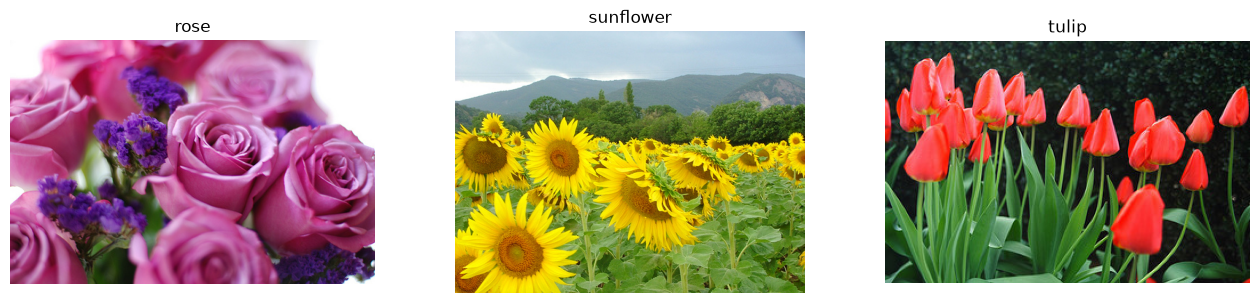

In [75]:
# preview original images from disk
train_ds = load_images("train", shuffle=True)
valid_ds = load_images("validation", shuffle=False)
class_names = train_ds.class_names

fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
for ax, name in zip(axes, class_names):
    image = keras.utils.load_img(next((flowers / "train" / name).glob("*.jpg")))
    ax.imshow(image)
    ax.set_title(name)
    ax.axis("off")
plt.show()

In [76]:
# check image size inside our data
images, labels = next(iter(train_ds))
images.shape

TensorShape([32, 160, 160, 3])

## Five photos of every flower

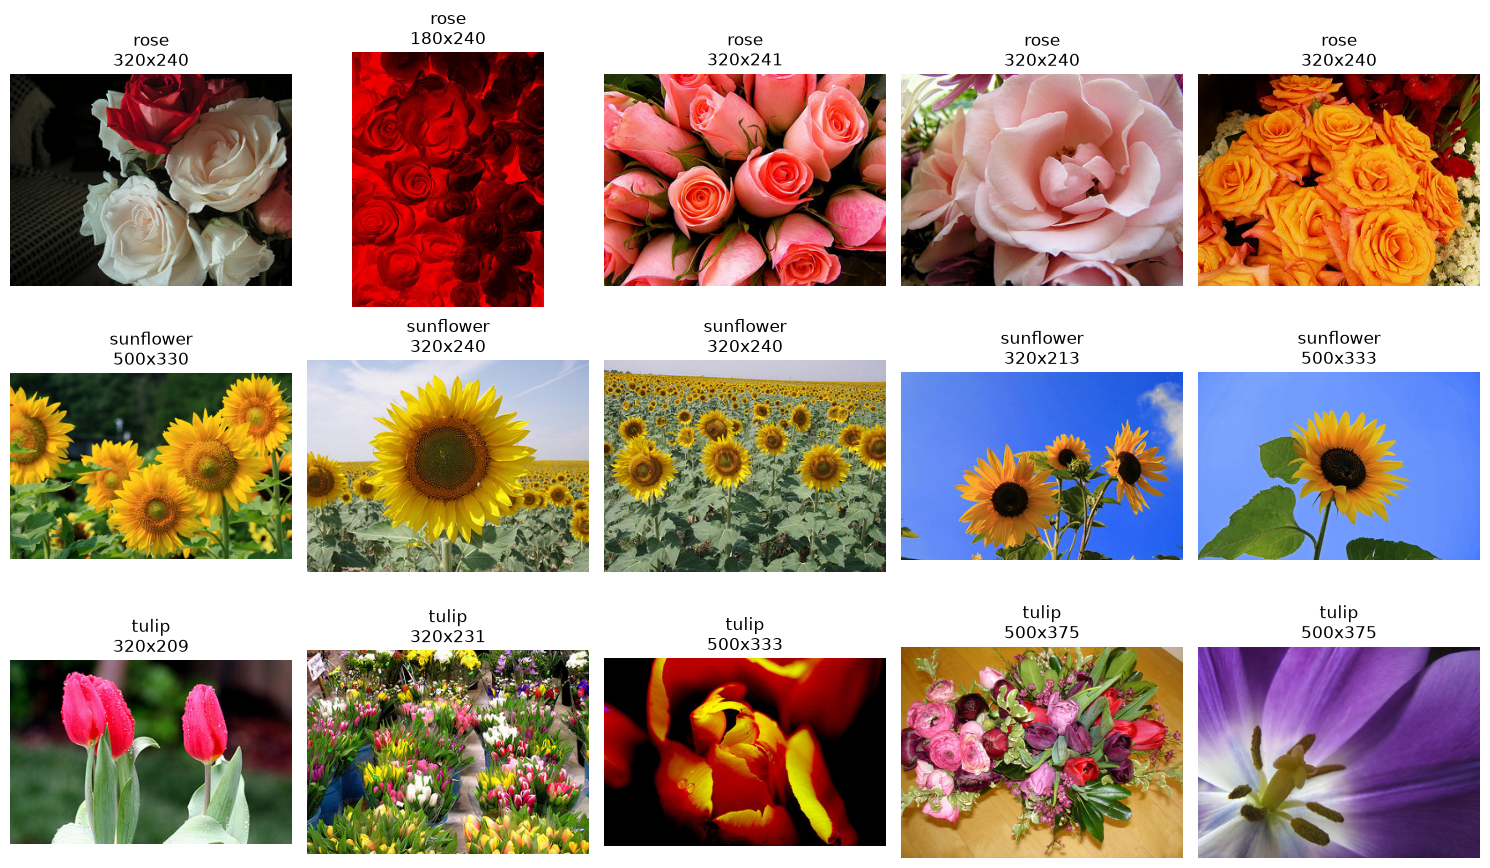

In [77]:
# Show the first 5 photos of every class
n_per_class = 5
fig, axes = plt.subplots(len(CLASSES), n_per_class, figsize=(15, 9))

for row, flower in enumerate(CLASSES):
    files = sorted(( flowers / "train" / flower).glob("*.jpg"))[:n_per_class]
    for col, file in enumerate(files):
        img = plt.imread(file)
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{flower}\n{img.shape[1]}x{img.shape[0]}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## What MobileNetV2 predicts out of the box

In [78]:
base = mobilenet_v2.MobileNetV2(
    include_top=True, weights="imagenet", input_shape=IMAGE_SIZE + (3,), pooling="avg"
)

Output shape: (32, 1000)
daisy                0.166
hair_slide           0.119
bee                  0.029


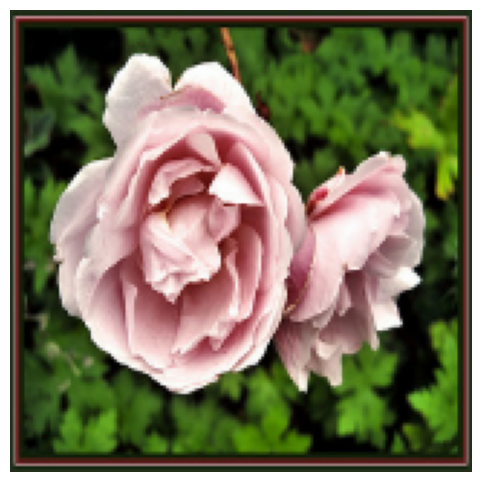

In [79]:
one_image,_ = next(iter(train_ds))

prepared = mobilenet_v2.preprocess_input(one_image)
probabilities = base.predict(prepared, verbose=0)  # shape (1, 1000)
print("Output shape:", probabilities.shape)
for _, name, probability in mobilenet_v2.decode_predictions(probabilities, top=3)[0]:
    print(f"{name:20s} {probability:.3f}")

plt.figure(figsize=(6, 6))
plt.imshow(one_image[0].numpy().astype("uint8"))
plt.axis("off")
plt.show()

# Transfer Learning

Reuse a **pretrained MobileNetV2** as a frozen feature extractor and train only a small classifier on top.

In [ ]:
# Base model
base2 = mobilenet_v2.MobileNetV2(
    include_top=False, weights="imagenet", input_shape=IMAGE_SIZE + (3,), pooling="avg"
)
base2.trainable = False

In [81]:
# helper function for extraction
def extract_features(dataset):
    """Run the frozen base over every batch of a dataset; return the feature vectors and the labels."""
    all_features = []
    all_labels = []
    for images, labels in dataset:  # one batch of up to 32 images at a time
        images = mobilenet_v2.preprocess_input(images)  # scale the pixels from 0 to 255 to -1 to 1
        features = base2.predict(images, verbose=0)  # one row of 1,280 numbers per image
        all_features.append(features)
        all_labels.append(labels.numpy())
    return np.concatenate(all_features), np.concatenate(all_labels)  # stack the batches into one table


In [82]:
def compile_and_fit(model, epochs, learning_rate=1e-3, initial_epoch=0):
    """Compile a classifier with Adam and train it on the bean images; return the learning curves."""
    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        metrics=["accuracy"],
    )
    history = model.fit(
        train_ds, validation_data=valid_ds, epochs=epochs, initial_epoch=initial_epoch, verbose=0
    )
    return pd.DataFrame(history.history, index=history.epoch)


def plot_curves(logs, title):
    """Plot the training and validation loss and accuracy of one run."""
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
    logs[["loss", "val_loss"]].plot(ax=ax_loss, xlabel="Epoch", title=f"{title}: loss")
    logs[["accuracy", "val_accuracy"]].plot(ax=ax_acc, xlabel="Epoch", title=f"{title}: accuracy")
    plt.show()

# Splitting the Data

Images are turned into **1280 features each** by the frozen base; every split is prepared identically.

In [83]:

X_train, y_train = extract_features(load_images("train", shuffle=False))
X_valid, y_valid = extract_features(valid_ds)

print("Training features:", X_train.shape, " validation features:", X_valid.shape)
print('labels', y_train.shape)

# Model 1: Dense Head

A small dense classifier trained on the extracted features.

In [ ]:


keras.utils.clear_session()
keras.utils.set_random_seed(42)

head = keras.Sequential(
    [
        keras.Input(shape=(X_train.shape[1],)),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(units=len(class_names), activation="softmax",
                           kernel_regularizer=keras.regularizers.L2(.1)),
    ]
)
# compile 
head.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.Adam(1e-3), metrics=["accuracy"])
# fitting
head_history = head.fit(X_train, y_train, epochs=30, verbose=0, validation_data=(X_valid, y_valid))

logs = pd.DataFrame(head_history.history, index=head_history.epoch)

## Validation result

In [85]:
test_loss, test_accuracy = head.evaluate(X_valid, y_valid, verbose=0)

print(f"Validation Loss: {test_loss:.4f}")
print(f"Validation Accuracy: {test_accuracy:.4f}")
print(f"Validation Accuracy: {test_accuracy * 100:.2f}%")

Validation Loss: 0.5765
Validation Accuracy: 0.8667
Validation Accuracy: 86.67%


## Learning curves

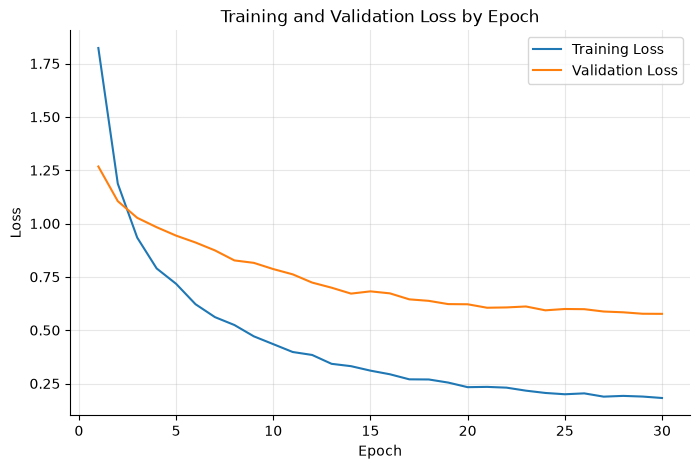

In [86]:
plt.figure(figsize=(8, 5))

plt.plot(logs.index + 1, logs["loss"], label="Training Loss")
plt.plot(logs.index + 1, logs["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss by Epoch")
plt.legend()
plt.grid(True)
plt.show()


# Model 2: With Augmentation

Random flips and rotations to reduce overfitting.

## Training with augmentation

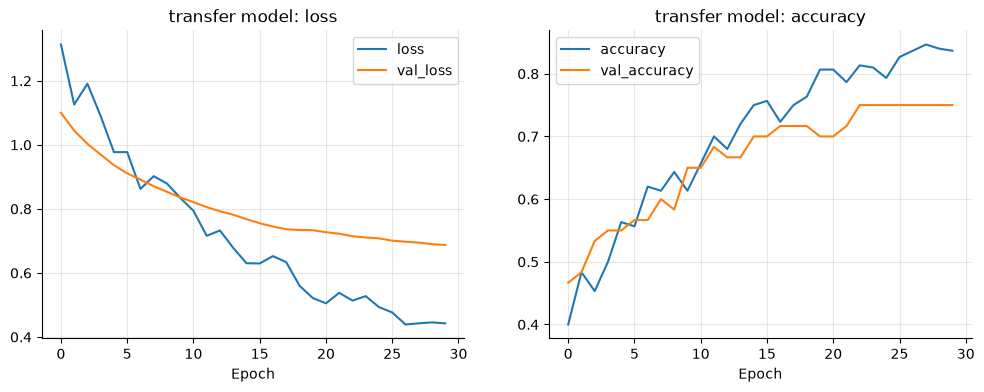

Validation accuracy: 0.750


In [87]:

keras.utils.clear_session()
keras.utils.set_random_seed(42)
augmentation = keras.Sequential(
    [keras.layers.RandomFlip("horizontal"), keras.layers.RandomRotation(0.1), keras.layers.RandomZoom(0.1)]
)
transfer_model = keras.Sequential(
    [
        keras.Input(shape=IMAGE_SIZE + (3,)),
        augmentation,
        keras.layers.Rescaling(scale=1 / 127.5, offset=-1),
        base2,
        keras.layers.Dropout(0.2),
        keras.layers.Dense(units=len(class_names), activation="softmax"),
    ]
)

transfer_model.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.Adam(1e-4), metrics=["accuracy"])

history = transfer_model.fit(train_ds, validation_data=valid_ds, epochs=30, verbose=0)

frozen_logs = pd.DataFrame(history.history, index=history.epoch)
plot_curves(frozen_logs, "transfer model")
results={}
results["transfer_model"] = transfer_model.evaluate(valid_ds, verbose=0)[1]
print(f"Validation accuracy: {results['transfer_model']:.3f}")

In [ ]:
# Save the models
Path("models").mkdir(exist_ok=True)

head.save("models/dense_head.keras")
transfer_model.save("models/augmented_model.keras")

# Testing on Unseen Photos

The 30 test photos are used **once**, at the very end. One photo = **3.3 percentage points**.

In [89]:
test_ds = load_images("test", shuffle=False)
X_test, y_test = extract_features(test_ds)

In [90]:
# load our models from file
plain_transfer = keras.models.load_model("models/dense_head.keras")
augmented_transfer = keras.models.load_model("models/augmented_model.keras")


## Test result and confusion matrix

*Model 1: Dense head*

 test accuracy: 0.933


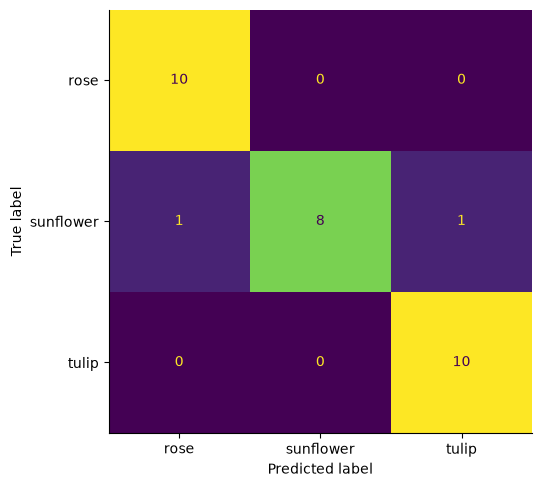

In [91]:
# get first model accuracy
print(f" test accuracy: {plain_transfer.evaluate(X_test, y_test, verbose=0)[1]:.3f}")
y_pred = plain_transfer.predict(X_test, verbose=0).argmax(axis=1)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names, colorbar=False, ax=ax)
ax.grid(False)
plt.show()

## Misclassified photos

*Model 1: Dense head*

Misclassified images: 2


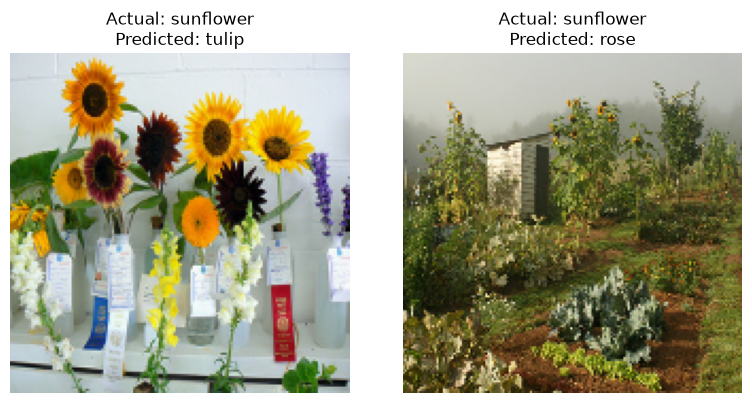

In [97]:
# plot wrong images for first model
X_test_images = np.concatenate([images.numpy() for images, labels in test_ds])
wrong_indices = np.where(y_test != y_pred)[0]

print(f"Misclassified images: {len(wrong_indices)}")

if len(wrong_indices) > 0:
    fig, axes = plt.subplots(
        1, len(wrong_indices),
        figsize=(4 * len(wrong_indices), 4)
    )

    if len(wrong_indices) == 1:
        axes = [axes]

    for ax, idx in zip(axes, wrong_indices):
        ax.imshow(X_test_images[idx].astype("uint8"))
        ax.set_title(
            f"Actual: {class_names[y_test[idx]]}\n"
            f"Predicted: {class_names[y_pred[idx]]}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No misclassified images!")

## Test result and confusion matrix

*Model 2: Augmented*

Augmented_transfer model accuracy score:  0.9


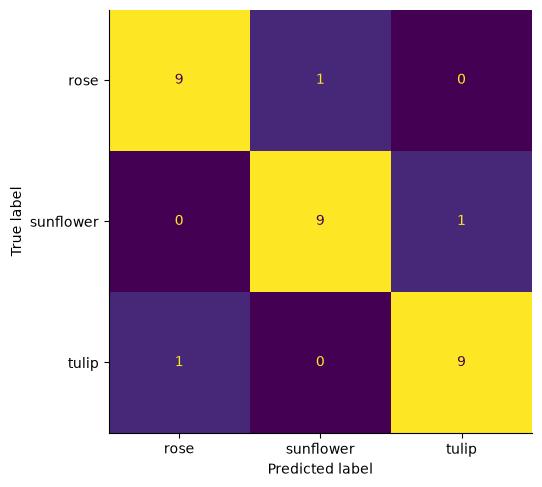

In [98]:
# test augmented model - model 2- 
y_test2 = np.concatenate([labels.numpy() for _, labels in test_ds])
pred = augmented_transfer.predict(test_ds, verbose=0).argmax(axis=1)

print('Augmented_transfer model accuracy score: ',accuracy_score(y_test2, pred))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test2, pred, display_labels=class_names, colorbar=False, ax=ax)
ax.grid(False)
plt.show()

## Misclassified photos

*Model 2: Augmented*

Number of misclassified images: 3


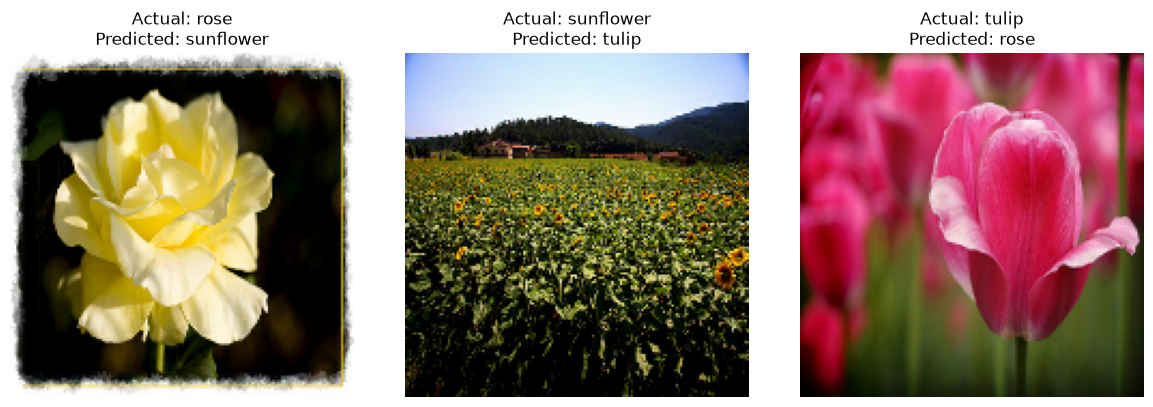

In [99]:
# Find incorrectly classified images
wrong_indices = np.where(y_test2 != pred)[0]

print(f"Number of misclassified images: {len(wrong_indices)}")

# Collect all test images
X_test = np.concatenate([images.numpy() for images, _ in test_ds])

# Display misclassified images
fig, axes = plt.subplots(
    1, len(wrong_indices),
    figsize=(4 * len(wrong_indices), 4)
)

if len(wrong_indices) == 1:
    axes = [axes]

for ax, idx in zip(axes, wrong_indices):
    ax.imshow(X_test[idx].astype("uint8"))
    ax.set_title(
        f"Actual: {class_names[y_test2[idx]]}\n"
           f"Predicted: {class_names[pred[idx]]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()